# USDJPY forward-return prediction (LightGBM)

Predict USDJPY from Yahoo Finance 1h bars (`yfinance`, `USDJPY=X`) with a leak-free walk-forward
evaluation. The project mirrors the experiment pipeline of `delivery-time-prediction`: versioned experiment
modules → one `execute()` call → leaderboard / diagnostics / experiments → refit → artefacts →
pre/post-analysis report.

There are three experiment arms; each changes one thing on top of the previous one:

| arm | objective | inputs | selection |
|---|---|---|---|
| `v003_cross_asset` (default) | **1-day forward log return**, `y_t = log(close[t+25] / close[t+1])` — the target of ml-pipe's `v001_logreturn_exp_v19_legacy_test` (`FWDLogReturn(48, 1)` on 30-min bars), regression | USDJPY + a 30-asset yfinance basket (FX, US yields, equity indices, VIX, commodities, BTC), ~7k features | Spearman |
| `v002_fwd_logret_1d` | same | USDJPY only, 234 features | Spearman |
| `v001_lgbm_walkforward` | next-hour direction, `close[t+1] > close[t]`, classification | USDJPY only | ROC AUC |

## Run it

Everything runs in Docker (`make help` lists the targets):

```bash
make build          # image with numpy/pandas/sklearn/lightgbm/yfinance/jupyter
make fetch          # ~2.8 years of 1h bars for USDJPY + the 30-asset basket -> dataset/ (the only network step)
make test           # unit tests on synthetic random-walk bars (no network)
make train          # v003 end-to-end -> outputs/ (leaderboard, holdout score, predictions.csv, model.joblib)
make train EXP=v002_fwd_logret_1d      # USDJPY-only features;  EXP=v001_lgbm_walkforward: next-hour direction
make predict        # forecast from the latest cached bar with the saved model
make experiments    # experiment ladder (TASK=return|direction; return = v003 data) -> outputs/experiments.json
make lineage        # sync experiment-lineage.json, render outputs/figures/lineage.png, print the best-MCC path (METRIC=mcc)
make run-report     # re-execute this notebook; `make report` exports REPORT.html; `make readme` refreshes README.md
```

Options: `EXP=<module>`, `MODELS=persistence,ridge,lgbm_reg` (empty = the arm's set), `CV=5`, `SEED=0`,
`COST=0.5` (bp per unit position change).

## Layout

| path | role |
|---|---|
| `usdjpy/data.py` | yfinance download + CSV cache for USDJPY and the `BASKET`, `align_basket` (as-of join onto the FX-week grid + staleness), targets, purged chronological holdout |
| `usdjpy/features.py` | `BarCleaner` (optional FX-week grid), `BarFeatureEngineer` (v001), `MultiWindowFeatureEngineer` (ml-pipe feature set, per asset), `ColumnSubset` (by asset / regex), encoders |
| `usdjpy/models.py` | direction candidates (`majority`, `momentum`, `logreg`, `lgbm`), return regressors (`persistence`, `mean`, `best_feature`, `random`, `ridge`, `lgbm_reg`) |
| `usdjpy/evaluation.py` | `DirectionEvaluator` / `ReturnEvaluator` (walk-forward `TimeSeriesSplit` + gap), ml-pipe's metric set + `rank_score`, slices (incl. market regime), displays |
| `usdjpy/pipeline/classification.py` | `execute()`: the 10 phases, task-aware |
| `usdjpy/analysis/` | builders, display helpers (banner, numbered headers, captions, figure saving), pre/post-analysis reporters |
| `usdjpy/style.py`, `usdjpy/regimes.py` | one palette + matplotlib chrome for every figure; the market-regime labels (joint trend × volatility grid, ml-pipe's trend / volatility deciles) shared by the regime slice and the regime figures |
| `usdjpy/exp/` | the experiment arms (copy the latest to `v00N_*.py` to change one thing; each carries a `DNA` dict) |
| `usdjpy/train.py`, `usdjpy/experiments.py` | CLI and experiment ladder |
| `usdjpy/lineage.py`, `experiment-lineage.json` | experiment DNA validation, run records per arm, the lineage tree (`make lineage`) |

## Method (v003, aligned with ml-pipe)

| | ml-pipe `v001_logreturn_exp_v19_legacy_test` | here (`v003_cross_asset`) |
|---|---|---|
| bars | 30 min, FX week Sun 17:00 → Fri 16:59 New York | 1h (Yahoo keeps 30-min history for 60 days only), same FX-week grid, missing hours forward-filled |
| target | `FWDLogReturn(lookahead_window=48, lookahead_offset=1)` | `log(close[t+25] / close[t+1])`: the same 1-day window after a 1-bar buffer |
| universe | USDJPY + ~40 Tiingo/Sharadar series (FX, macro), non-FX series forward-filled onto the FX grid, then asset / feature-type selection by Spearman importance | USDJPY + 30 yfinance assets (14 FX crosses, DXY, US 13w/5y/10y/30y, N225/SPX/VIX/FTSE/DAX/HSI, gold/oil/silver/copper, BTC), as-of joined onto the FX-week grid with an hours-since-last-print column; no selection yet (v004) |
| features | 18 `tsf` types × windows 1.5h…63d × shifts {0, 1 day} per asset | the same 18 types and clock windows (2, 6, 12, 24, 120, 504, 1512 bars) × shifts {0, 23} per asset: ~7.3k features |
| model | feature selection → sparse mixture-of-experts net, robust-scaled/clipped target | `LGBMRegressor` (30% column sampling per tree) on a robust-scaled, ±5-clipped target |
| baselines | persistence, mean, best_feature, random_sample | persistence, mean, best_feature, random, + ridge |
| validation | rolling 1.5y train, 16-day skip, 6-month roll | 5-fold walk-forward, 16-day gap (274 bars); rolling 1.5y window as an experiment; last 15% held out, purged by 25 bars |
| metrics | MSE, MAE, R², Pearson, Spearman, Kendall, F1, ROC AUC, MCC (+ weighted τ, Wasserstein, precision/recall, sign-strategy Sharpe); leaderboard = weighted rank score | the same set: Spearman (selection), Pearson, Kendall, weighted τ, R², MSE, MAE, Wasserstein, MCC, F1, precision, recall, ROC AUC, binary accuracy, ml-pipe's `sharpe_ratio`, plus our daily non-overlapping sign trade and ml-pipe's `rank_score` |
| post-analysis | generalization gap (in- vs out-of-sample), rolling metrics, regime slices, residual report (ACF, trend, heteroskedasticity, normality) | the same: generalization gap on the 80/20 fit, rolling Spearman, trend × volatility regime slices, residual ACF / trend / rolling std / Jarque–Bera / ARCH-LM |

## Report

`make train` (and this notebook) render two numbered sections and save every figure to `outputs/figures/`:

| section | what it shows | figures |
|---|---|---|
| Pre-analysis 1–7 | coverage, **market context** (close, volatility, drawdown, holdout span), target distribution + label ACF, return ACF, **regimes** (timeline of the joint trend × volatility grid, target by regime, ml-pipe's past / future trend and volatility deciles, hour × weekday seasonality), **cross-asset** (basket correlation, rolling correlation with USDJPY, feed freshness), feature–target correlation by asset group × feature type | `pre_*.png` |
| Post-analysis 1–11 | run record, leaderboard with per-fold ranges, training curves + generalisation dumbbell, experiments, **performance over time** (rolling Spearman / hit rate / equity / prediction band against regimes and folds, year × month calendar), slices, **regime performance** (joint grid, ml-pipe decile violins, predicted vs realised), residuals (ACF, trend, heteroskedasticity, Q–Q, residual vs fitted, CUSUM), importance by asset / type, holdout timeline, verdict | `post_*.png`, `<model>.png`, `holdout_<model>.png` |

**Leakage guards.**
- Every feature is invariant to truncating or shocking the future (tested).
- A random walk scores Spearman ≈ 0 through the evaluator.
- No development label overlaps the holdout or a test fold.

The cells below re-run v003 and render the full report.

In [1]:
%matplotlib inline
import json, warnings
from pathlib import Path

import pandas as pd
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

from usdjpy import style
from usdjpy.analysis import display_dataframe, display_info_box
from usdjpy.exp import v003_cross_asset as exp

style.use()                       # same palette / chrome for any ad-hoc plots below

[v003_cross_asset] Step2: 17,486 bars -> 13,512 dev rows + 2,389 holdout rows (from 2026-06-10 23:00:00+00:00)


,count
gap length,
48h,3
49h,120
50h,2


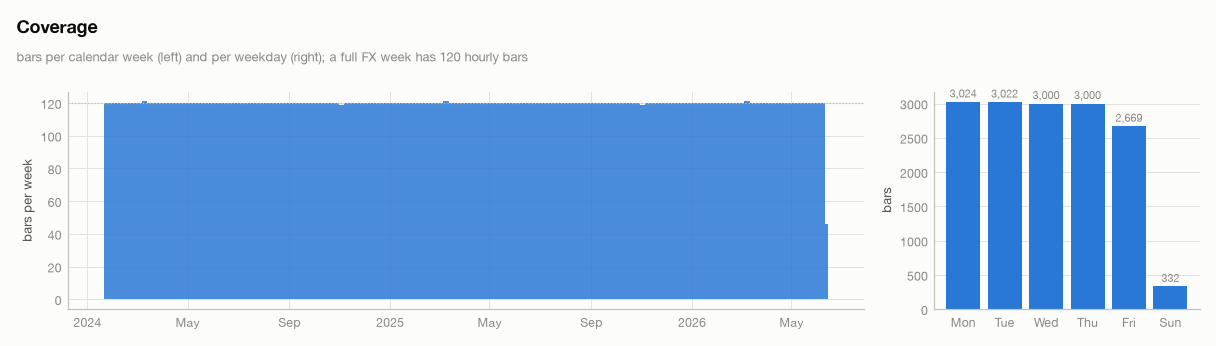

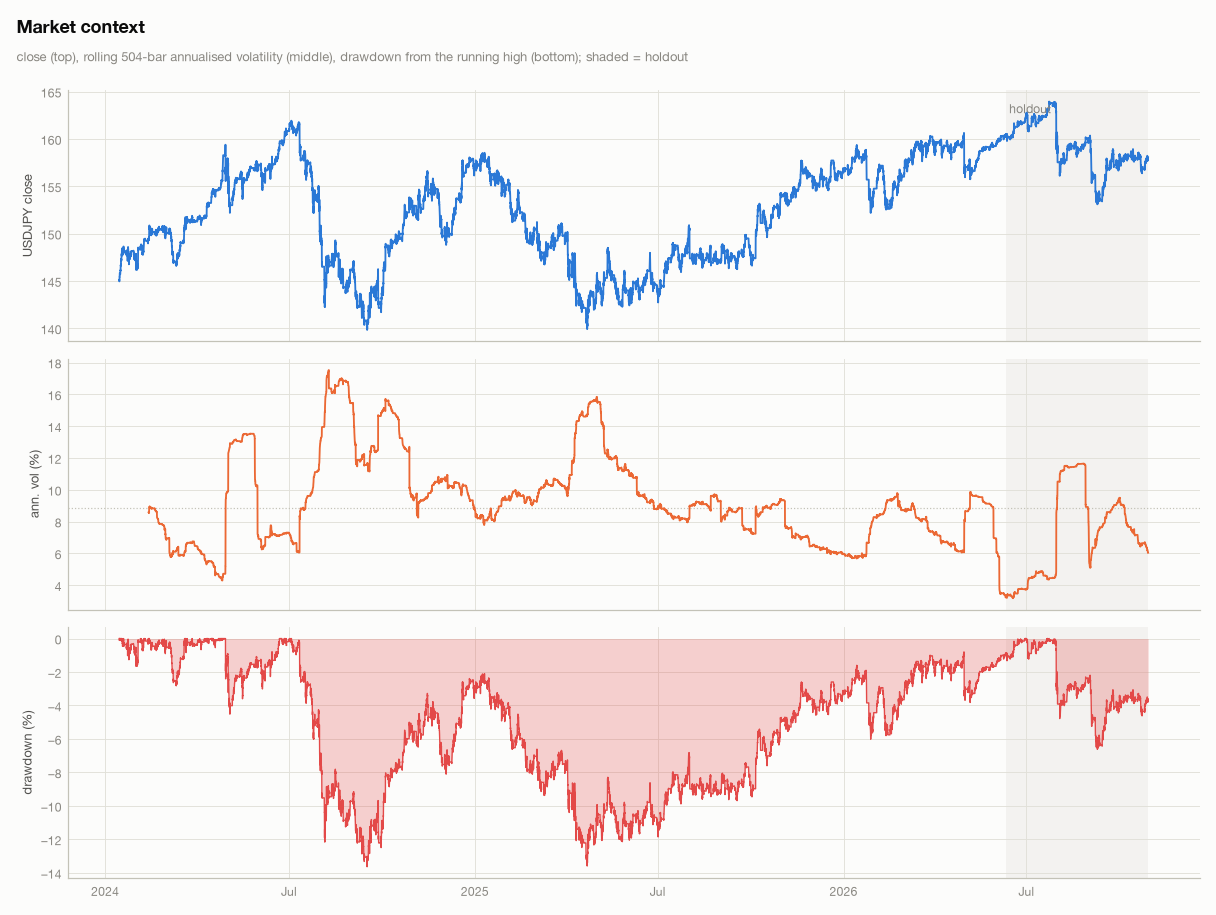

,mean_bp,std_bp,skew,kurtosis,p01_bp,p99_bp,up_share,n
forward log return,0.8242,63.0046,-0.7693,3.6276,-197.0852,155.4334,0.5629,13512


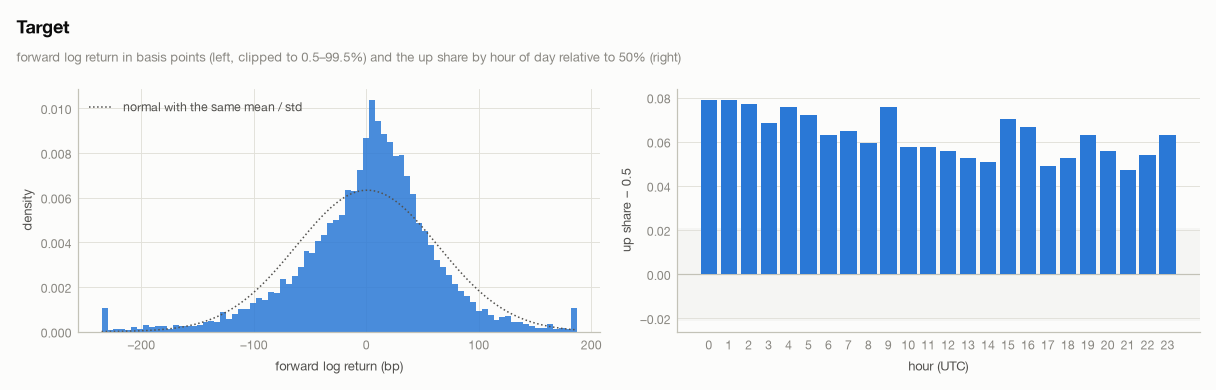

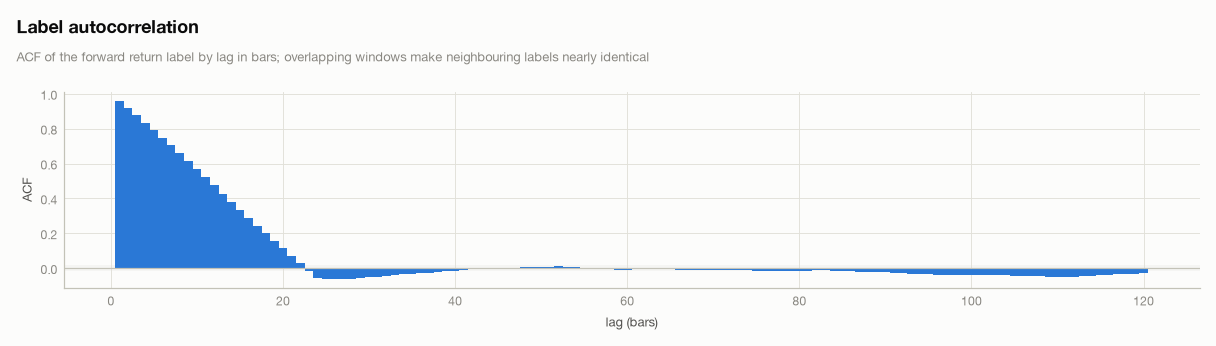

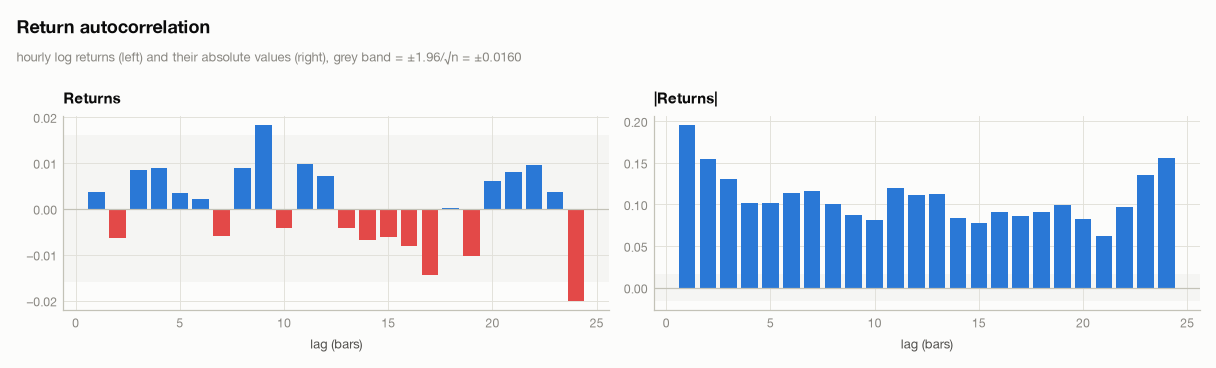

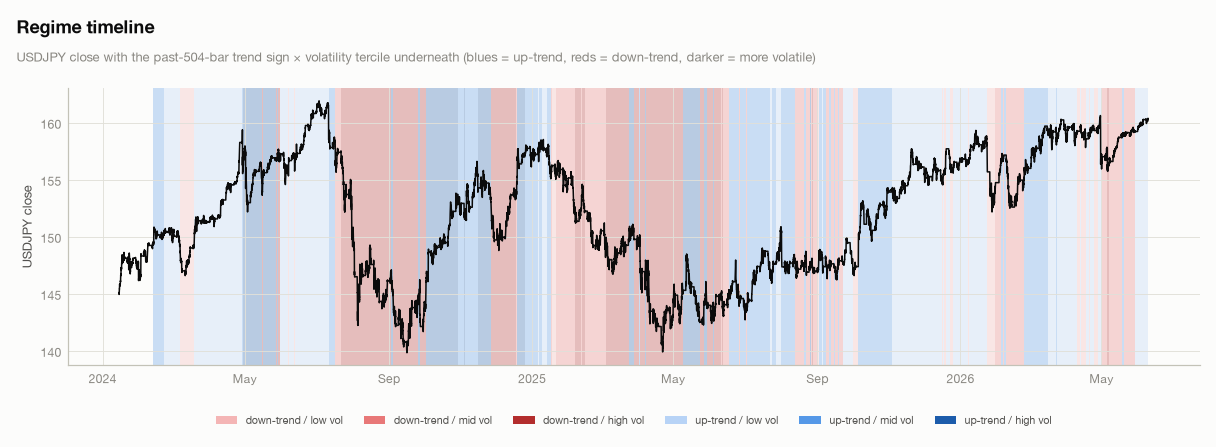

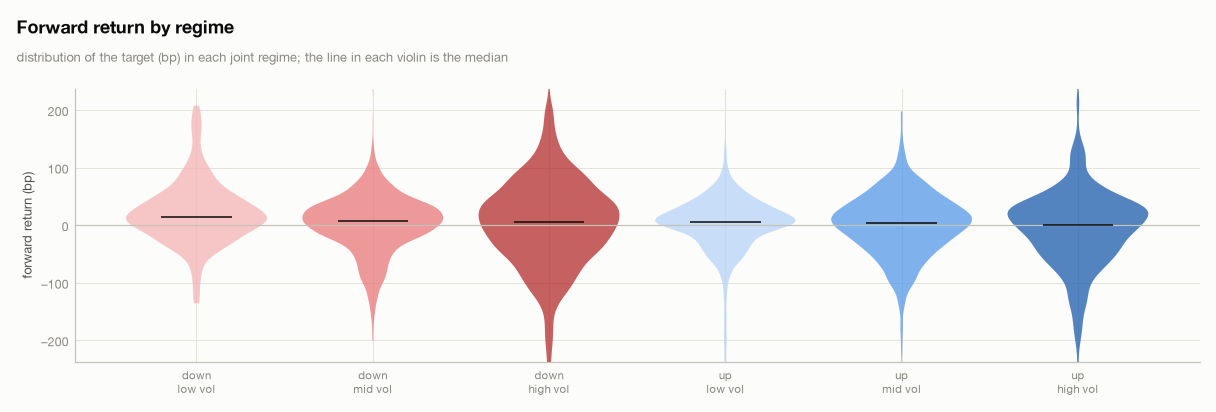

,n,share,mean_bp,std_bp,up_share,mean_spell_bars
regime,,,,,,
down-trend / low vol,590,0.0437,21.4489,55.8243,0.6780,12.5532
down-trend / mid vol,1957,0.1448,2.0053,50.5232,0.5795,31.0635
down-trend / high vol,3016,0.2232,1.2226,81.4702,0.5411,52.0000
up-trend / low vol,3398,0.2515,0.1247,52.9895,0.5983,54.8065
up-trend / mid vol,2719,0.2012,0.5910,56.1909,0.5417,40.5821
up-trend / high vol,1832,0.1356,-6.0919,67.4453,0.5098,37.3878


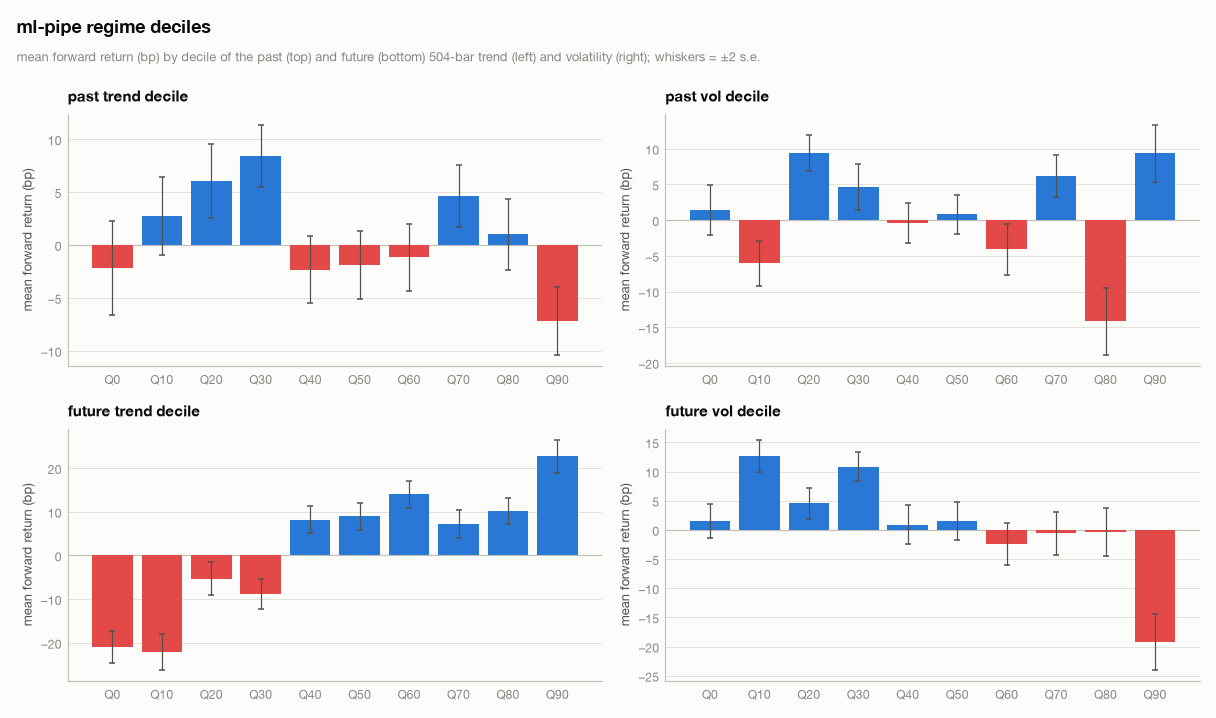

past trend                past vol                future trend                future vol               
       mean_bp up_share     n  mean_bp up_share     n      mean_bp up_share     n    mean_bp up_share     n
g                                                                                                          
Q0     -2.1956   0.5388  1455   1.4873   0.6502  1135     -20.9685   0.4378  1455     1.4863   0.5503   865
Q10     2.7566   0.5516  1414  -6.0595   0.5399  1052     -22.0175   0.4364  1414    12.6479   0.6445  1052
Q20     6.0583   0.5960  1344   9.4438   0.6328  1337      -5.3460   0.5201  1344     4.5659   0.5931  1337
Q30     8.3896   0.5938  1418   4.5997   0.5688  1396      -8.8382   0.4803  1418    10.8462   0.6235  1397
Q40    -2.3234   0.5575  1356  -0.3536   0.5064  1321       8.1905   0.6093  1354     0.9143   0.5361  1317
Q50    -1.8862   0.5654  1231   0.8110   0.5605  1454       8.9705   0.6402  1209     1.5942   0.5582  1451
Q60    -1.1602   0.5554  1246  -4.0889   0.5695  1454      14.0112   0.6622  1181    -2.4301   0.5165  1398
Q70     4.6136   0.6202  1314   6.2142   0.5784  1454       7.2628   0.5615  1147    -0.5925   0.5200  1452
Q80     1.0184   0.5446  1322 -14.1893   0.4876  1454      10.2105   0.5912  1206    -0.3224   0.5378  1283
Q90    -7.1499   0.5099  1412   9.3504   0.5485  1455      22.6775   0.6646  1279   -19.1905   0.4955  1455

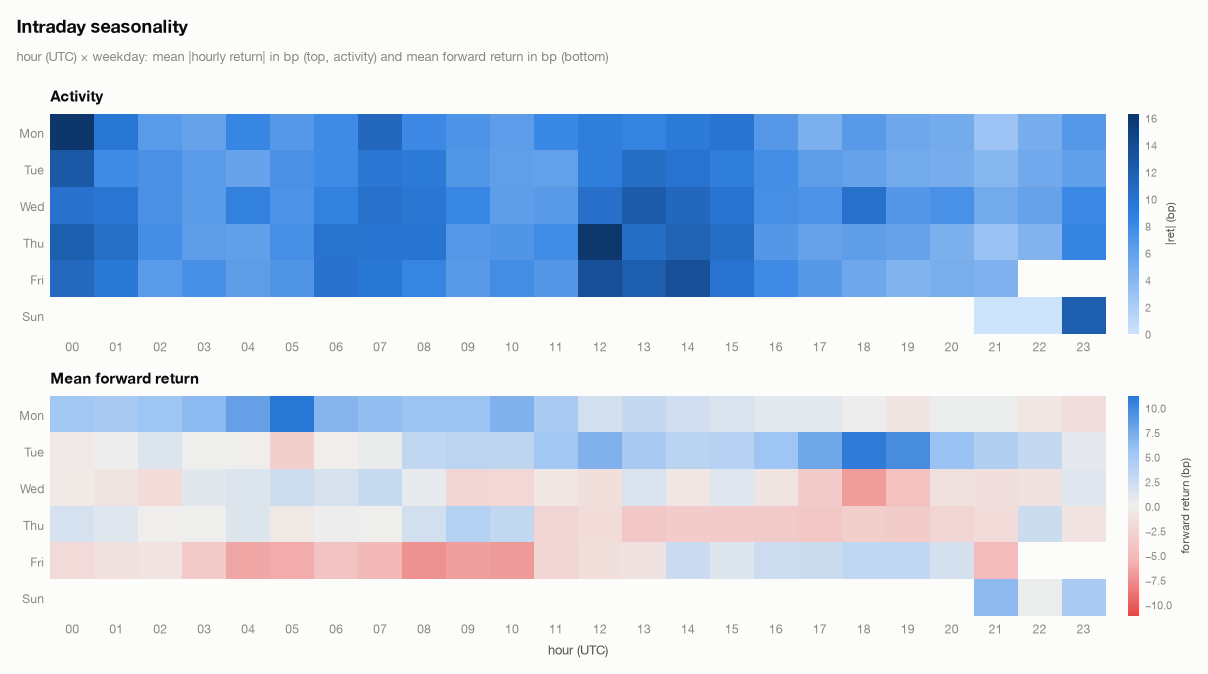

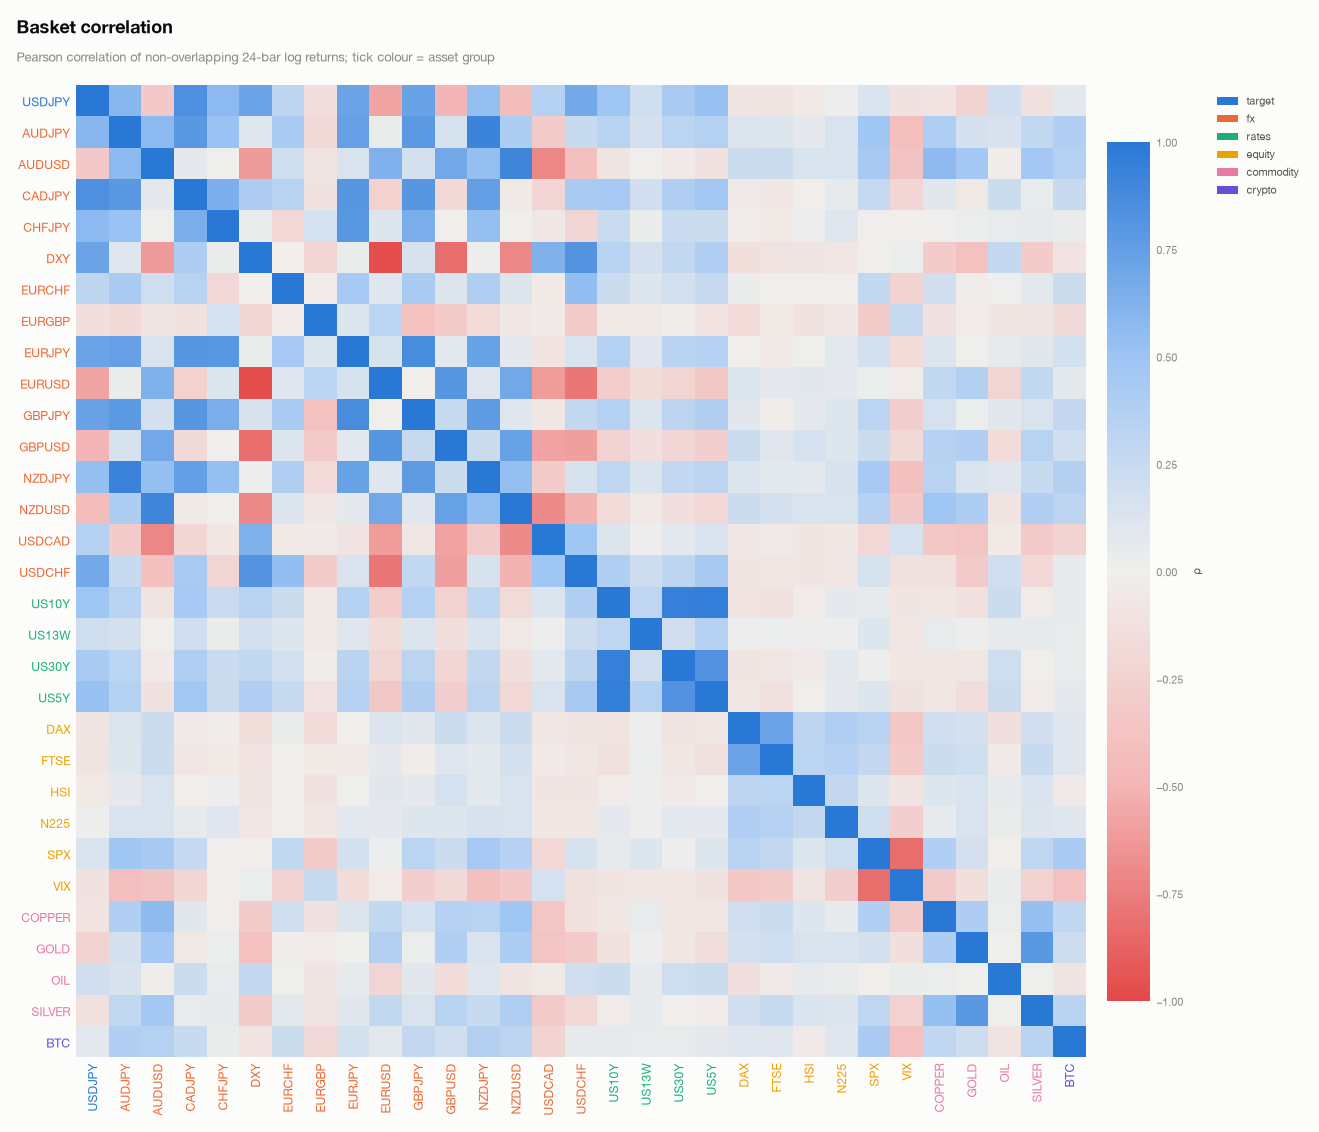

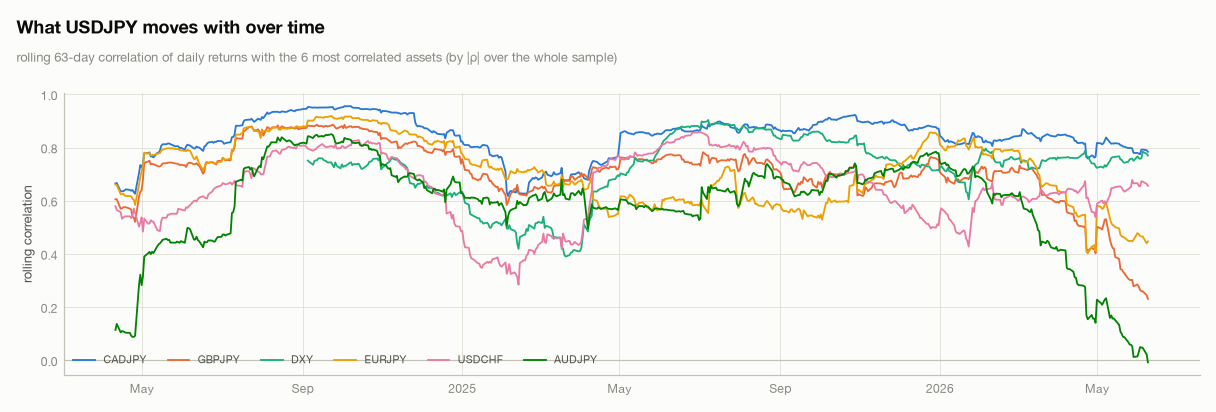

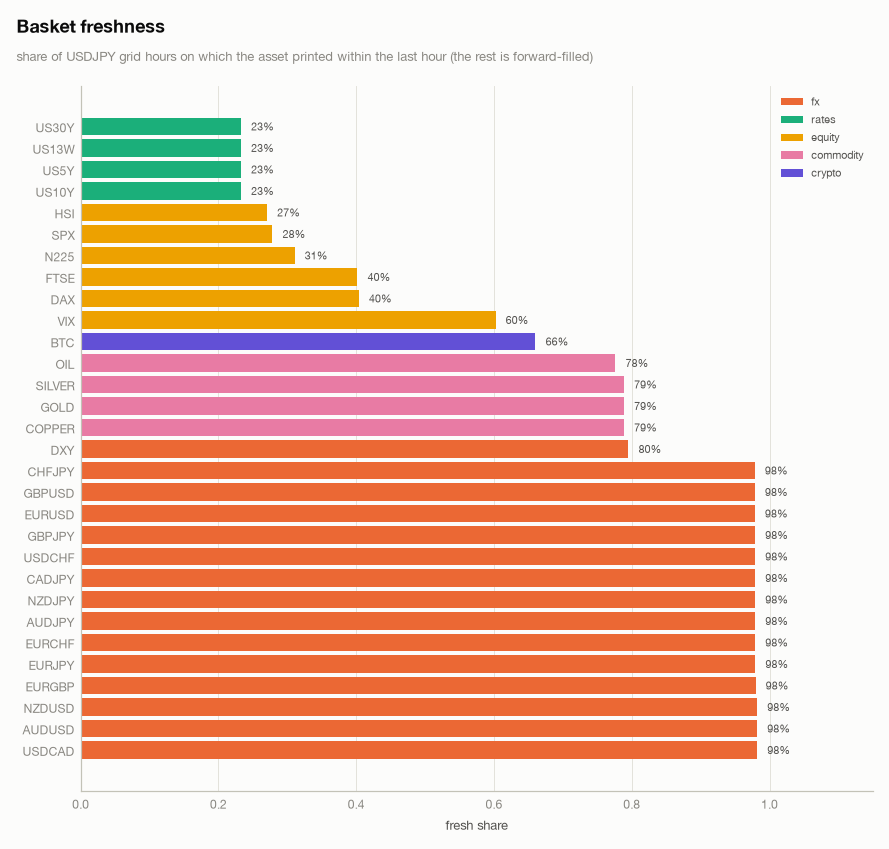

,mean,std,min,max,missing,spearman_target
NZDUSD__diff_w120_s23,-0.0001,0.0076,-0.0248,0.0389,0.0000,0.1217
NZDUSD__pct_change_w120_s23,-0.0002,0.0130,-0.0389,0.0702,0.0000,0.1217
NZDUSD__drawdown_w120_s23,0.0091,0.0077,0.0000,0.0565,0.0000,-0.1200
NZDUSD__rsi_w120_s23,-0.0049,0.1292,-0.4004,0.4059,0.0000,0.1197
US5Y__change_kurt_w504_s0,29.7099,17.5346,0.0000,90.8887,0.0000,-0.1179
NZDUSD__zscore_w120_s23,-0.0442,1.3938,-3.0000,3.0000,0.0000,0.1161
NZDJPY__we_volatility_w120_s0,0.4605,0.2669,0.0894,2.3111,0.0000,-0.1115
DXY__change_kurt_w504_s23,11.3490,11.8279,0.0000,58.7929,0.0000,-0.1107
US5Y__we_volatility_w120_s0,0.0429,0.0247,0.0089,0.2039,0.0792,-0.1105
GBPJPY__drawup_w24_s0,0.0036,0.0034,0.0000,0.0281,0.0000,-0.1094


Largest |ρ| = 0.1217 (n = 13,512; ±2σ noise ≈ 0.0172). Single features carry very little linear signal.

,mean,max,size,group
asset,,,,
SILVER,0.0332,0.0973,235,commodity
NZDUSD,0.0315,0.1217,235,fx
US13W,0.0306,0.0904,235,rates
AUDUSD,0.0297,0.1040,235,fx
EURCHF,0.0292,0.1047,235,fx
GBPJPY,0.0287,0.1094,235,fx
SPX,0.0286,0.0920,235,equity
EURJPY,0.0278,0.1018,235,fx
COPPER,0.0270,0.0977,235,commodity


,mean,max,size
type,,,
pct_change,0.0266,0.1217,434
diff,0.0265,0.1217,434
zscore,0.0262,0.1161,372
rsi,0.0258,0.1197,434
macd,0.0249,0.1054,372
drawup,0.0248,0.1094,434
macd_diff,0.0246,0.1058,372
change_skew,0.0246,0.0977,372
wema_div,0.0245,0.0977,434


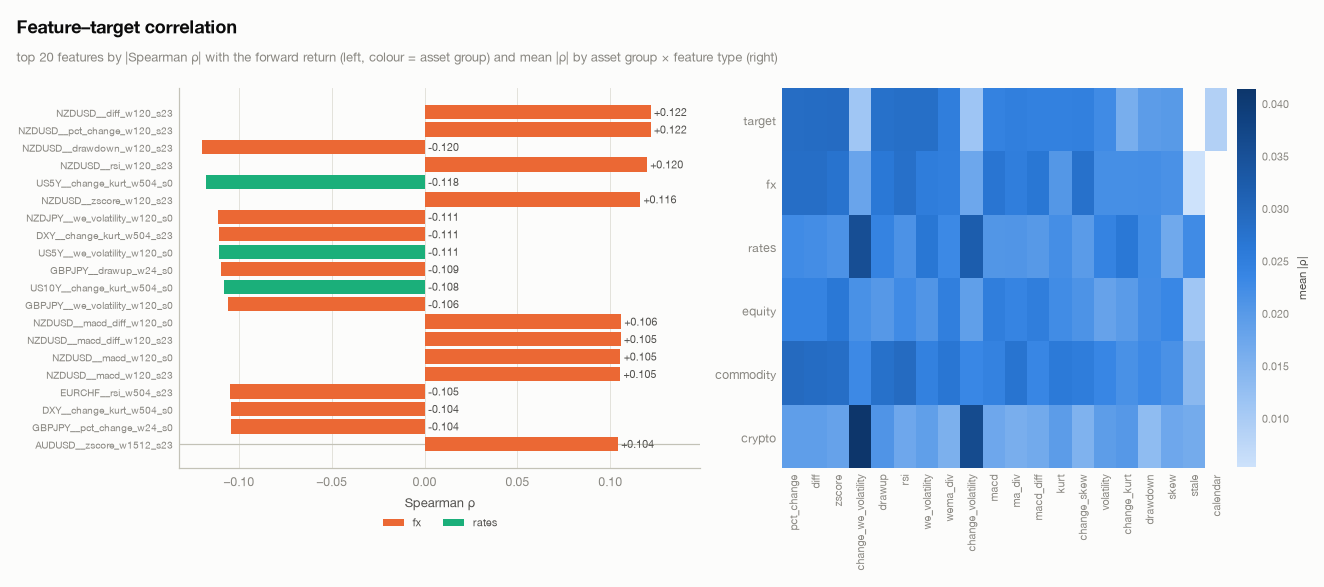

[v003_cross_asset] Step4: 6 candidates: ['persistence', 'mean', 'best_feature', 'random', 'ridge', 'lgbm_reg']


[v003_cross_asset] Step5: walk-forward CV with TimeSeriesSplit(gap=274, max_train_size=None, n_splits=5, test_size=None)


[cv] persistence


  [persistence] fold 0: spearman=-0.1216 hit=0.4556 strat=-7.667bp (0.2s)


  [persistence] fold 1: spearman=-0.0931 hit=0.4636 strat=+4.217bp (0.2s)


...

[v003_cross_asset] Step7: lgbm_reg (rolling ~1.5y window): spearman=0.0613


[v003_cross_asset] Step8: refit lgbm_reg on all 13,512 development rows


[v003_cross_asset] Step8: holdout spearman 0.0665, hit 0.5036, strategy +3.214 bp/day


[v003_cross_asset] Step9: artefacts under /Users/alhabib/Desktop/glitcj-repos/alpha-discovery/usdjpy-direction/outputs (347.3s)


,spearman,spearman_fold_std,pearson,kendall,weighted_tau,r2,mse,mae,wasserstein,mcc,f1,precision,recall,roc_auc,bin_acc,sharpe_ratio,strategy_bps,sharpe,rank_score,n,fit_time_s
model,,,,,,,,,,,,,,,,,,,,,
lgbm_reg,0.0599,0.1029,0.0572,0.0399,-0.1012,-0.2025,0.0000,0.0050,0.0025,0.0570,0.4905,0.5935,0.4180,0.5292,0.5152,1.0163,5.0469,1.3348,21.7500,11260.0000,14.5076
ridge,0.0438,0.0712,-0.0009,0.0302,-0.1070,-26.9305,0.0010,0.0159,0.0113,0.0514,0.6284,0.5763,0.6909,0.5198,0.5438,1.0115,5.2086,1.3774,15.2500,11260.0000,7.1945
random,0.0023,0.0145,0.0053,0.0015,0.1039,-1.4804,0.0001,0.0071,0.0007,0.0013,0.5543,0.5590,0.5497,0.5024,0.5064,-0.0370,0.7813,0.2057,15.7500,11260.0000,0.2304
best_feature,-0.0322,0.0605,-0.0633,-0.0222,-0.1633,-4.1527,0.0002,0.0092,0.0041,0.0192,0.5207,0.5684,0.4804,0.4979,0.5062,-0.3052,-1.0057,-0.2650,11.2500,11260.0000,7.5818
persistence,-0.0592,0.0637,-0.0738,-0.0398,-0.1345,-1.1466,0.0001,0.0066,0.0000,-0.0237,0.5472,0.5478,0.5465,0.4707,0.4949,-0.5414,-7.1635,-1.8976,9.2500,11260.0000,0.2447
mean,-0.0668,0.0401,-0.0650,-0.0457,-0.1117,-0.0665,0.0000,0.0046,0.0035,-0.0493,0.5408,0.5369,0.5448,0.4737,0.4835,-1.1059,-4.2611,-1.1252,10.7500,11260.0000,0.2314


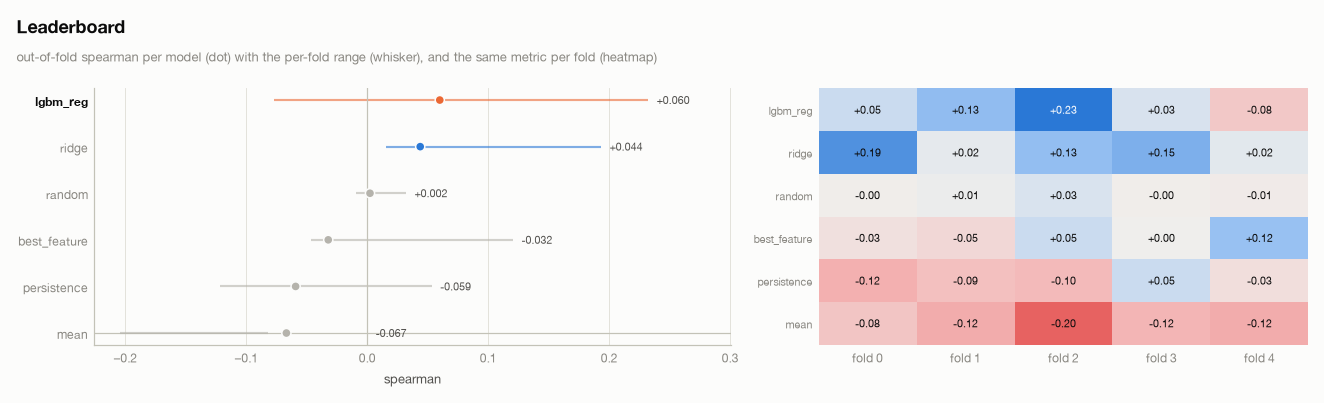

,test_start,test_end,n_train,n_test,spearman,pearson,kendall,weighted_tau,r2,mse,...,precision,recall,roc_auc,bin_acc,sharpe_ratio,pred_up_share,auc,hit_rate,strategy_bps,sharpe
fold,,,,,,,,,,,,,,,,,,,,,
0,2024-08-21 18:00:00+00:00,2024-12-31 14:00:00+00:00,1978,2252,0.0541,0.0205,0.0342,-0.0982,-0.4210,0.0001,...,0.6303,0.1963,0.5143,0.4720,-0.7690,0.1790,0.5143,0.4720,-3.9429,-0.8935
1,2024-12-31 15:00:00+00:00,2025-05-12 09:00:00+00:00,4230,2252,0.1286,0.1298,0.0849,-0.0330,-0.0581,0.0001,...,0.5213,0.6043,0.5665,0.5466,1.6551,0.5528,0.5665,0.5466,5.3316,1.2116
2,2025-05-12 10:00:00+00:00,2025-09-19 05:00:00+00:00,6482,2252,0.2323,0.2803,0.1623,0.0177,0.0243,0.0000,...,0.6066,0.3501,0.6040,0.5506,2.3810,0.2957,0.6040,0.5506,10.0552,2.7170
3,2025-09-19 06:00:00+00:00,2026-01-29 02:00:00+00:00,8734,2252,0.0337,0.0608,0.0219,0.2050,-0.3633,0.0000,...,0.5739,0.3872,0.4988,0.4951,1.3798,0.3783,0.4988,0.4951,5.1520,1.5345
4,2026-01-29 03:00:00+00:00,2026-06-09 21:00:00+00:00,10986,2252,-0.0772,-0.0524,-0.0520,-0.1003,-0.2351,0.0000,...,0.6593,0.5539,0.4582,0.5115,0.7468,0.5604,0.4582,0.5115,5.0638,1.8904


,spearman,pearson,kendall,weighted_tau,r2,mse,mae,wasserstein,mcc,f1,precision,recall,roc_auc,bin_acc,sharpe_ratio,strategy_bps,sharpe,fit_time_s
model,,,,,,,,,,,,,,,,,,
lgbm_reg,-0.0164,0.0106,-0.0098,-0.0614,-0.1468,0.0000,0.0038,0.0018,-0.0014,0.6206,0.6553,0.5895,0.4919,0.5274,0.8259,8.4264,2.6313,20.9043


,spearman,pearson,kendall,weighted_tau,r2,mse,mae,wasserstein,mcc,f1,...,recall,roc_auc,bin_acc,sharpe_ratio,pred_up_share,auc,hit_rate,strategy_bps,sharpe,in_sample_spearman
model,,,,,,,,,,,,,,,,,,,,,
lgbm_reg,0.9516,0.9355,0.8006,0.9858,1.0109,-0.0,-0.0021,-0.0007,0.8,0.2879,...,0.3257,0.4709,0.3727,14.6684,-0.0399,0.4709,0.3727,36.4936,13.2858,0.9352


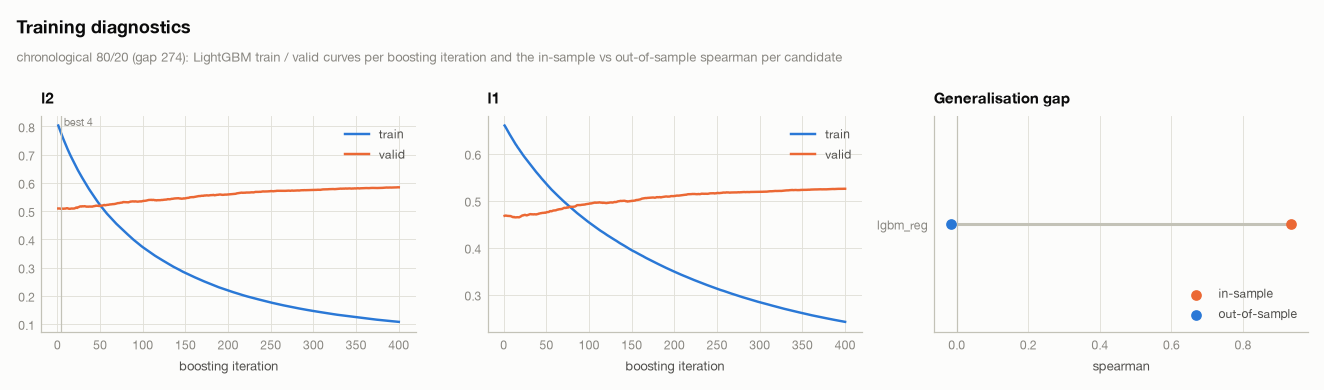

,spearman,spearman_fold_std,pearson,kendall,weighted_tau,r2,mse,mae,wasserstein,mcc,f1,precision,recall,roc_auc,bin_acc,sharpe_ratio,strategy_bps,sharpe,rank_score,n,fit_time_s
model,,,,,,,,,,,,,,,,,,,,,
lgbm_reg (rolling ~1.5y window),0.0613,0.0985,0.0587,0.0409,-0.1016,-0.2031,0.0000,0.0050,0.0024,0.0616,0.5010,0.5954,0.4325,0.5317,0.5190,1.0223,3.7429,0.9881,18.7500,11260.0000,9.0908
lgbm_reg,0.0599,0.1029,0.0572,0.0399,-0.1012,-0.2025,0.0000,0.0050,0.0025,0.0570,0.4905,0.5935,0.4180,0.5292,0.5152,1.0163,5.0469,1.3348,16.7500,11260.0000,14.5076
lgbm_reg (FX assets only),0.0401,0.0943,0.0271,0.0274,-0.0632,-0.2639,0.0000,0.0051,0.0020,0.0344,0.5538,0.5748,0.5343,0.5247,0.5193,0.3201,2.7251,0.7184,11.5000,11260.0000,4.6150
lgbm_reg (non-FX assets only),0.0190,0.0252,0.0306,0.0118,-0.0114,-0.2936,0.0000,0.0052,0.0025,0.0098,0.4430,0.5648,0.3644,0.5145,0.4884,0.1499,4.4789,1.1840,8.7500,11260.0000,5.7113
lgbm_reg (USDJPY only = v002),-0.0156,0.0337,-0.0279,-0.0100,-0.0831,-0.7182,0.0001,0.0059,0.0020,-0.0173,0.4504,0.5476,0.3825,0.4939,0.4788,-0.2053,-0.7057,-0.1859,4.2500,11260.0000,1.6959


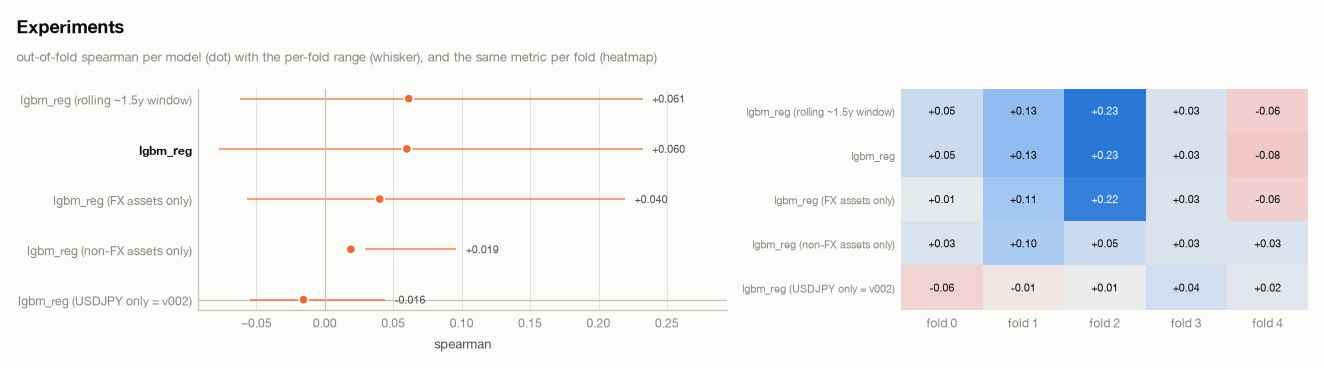

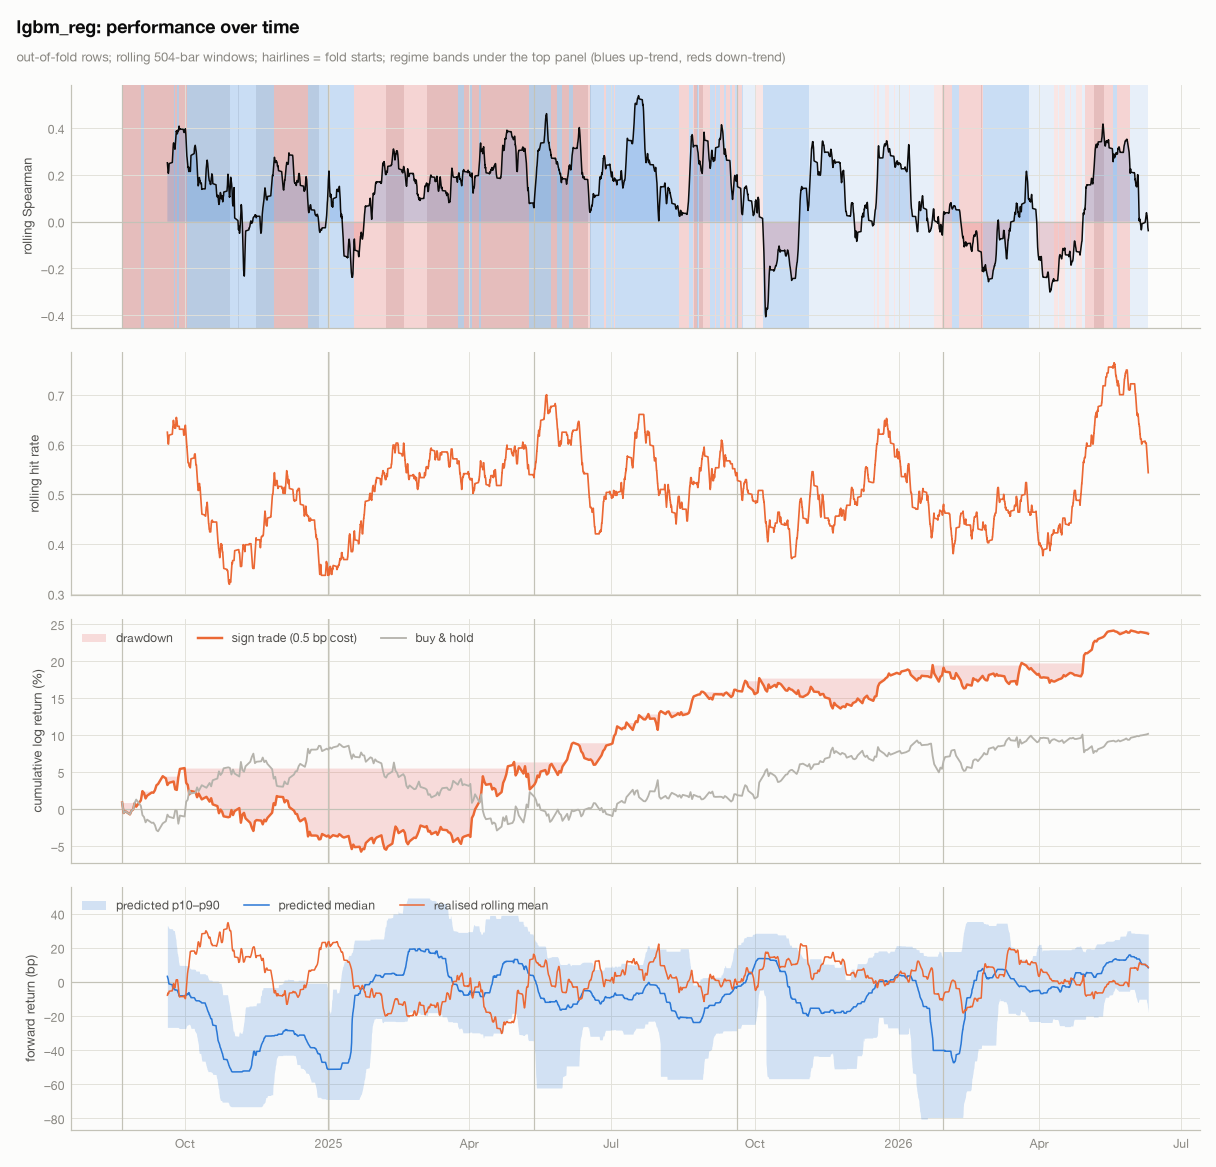

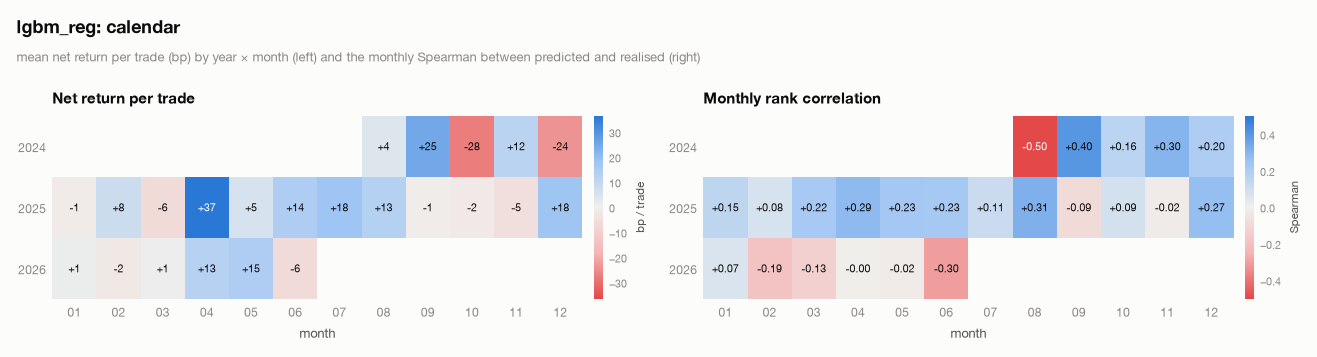

,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
tokyo,3283.0000,0.2916,0.5705,2.1028,0.0361,0.5041
tokyo+london,938.0000,0.0833,0.5554,2.0759,0.0461,0.5139
london,1407.0000,0.1250,0.5558,2.0326,0.0587,0.5210
london+ny,1876.0000,0.1666,0.5522,1.9930,0.0730,0.5219
ny,2348.0000,0.2085,0.5515,2.0976,0.0880,0.5277
off-hours,1408.0000,0.1250,0.5483,2.0643,0.0580,0.5064


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
00-03,1876.0000,0.1666,0.5730,2.0822,0.0348,0.4952
04-07,1876.0000,0.1666,0.5650,2.1158,0.0412,0.5128
08-11,1876.0000,0.1666,0.5549,2.0442,0.0549,0.5219
12-15,1876.0000,0.1666,0.5522,1.9930,0.0730,0.5219
16-19,1878.0000,0.1668,0.5517,2.0861,0.0903,0.5261
20-23,1878.0000,0.1668,0.5490,2.0841,0.0626,0.5133


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
Mon,2256.0000,0.2004,0.5448,2.2505,0.0325,0.5164
Tue,2254.0000,0.2002,0.5856,6.0976,-0.0007,0.5009
Wed,2238.0000,0.1988,0.5590,2.1593,0.0205,0.5143
Thu,2256.0000,0.2004,0.5652,-1.1621,0.2278,0.5496
Fri,2010.0000,0.1785,0.5343,0.5010,0.0232,0.4950
Sun,246.0000,0.0218,0.5285,5.0485,-0.0123,0.4919


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
low vol,3754.0000,0.3334,0.5725,3.4419,-0.0460,0.4893
mid vol,3753.0000,0.3333,0.5867,5.4249,0.0798,0.4905
high vol,3753.0000,0.3333,0.5137,-2.6645,0.1547,0.5657


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
down-trend / low vol,693.0000,0.0615,0.7013,22.6979,0.0514,0.5873
down-trend / mid vol,1772.0000,0.1574,0.5581,-0.7734,0.0403,0.5739
down-trend / high vol,2416.0000,0.2146,0.5724,8.5768,0.0531,0.5240
up-trend / low vol,3061.0000,0.2718,0.5528,-2.4254,-0.0611,0.4613
up-trend / mid vol,1981.0000,0.1759,0.5593,2.9525,0.1680,0.4952
up-trend / high vol,1337.0000,0.1187,0.4645,-7.6472,-0.0950,0.5370


,n,share,up_share,mean_y_bp,spearman,hit_rate
slice,,,,,,
q1 (smallest |pred|),2815.0000,0.2500,0.5822,5.6766,0.0923,0.5144
q2,2815.0000,0.2500,0.5822,6.6068,0.0678,0.5467
q3,2815.0000,0.2500,0.5400,-0.7873,0.0754,0.5169
q4 (largest |pred|),2815.0000,0.2500,0.5261,-3.2257,-0.0268,0.4828


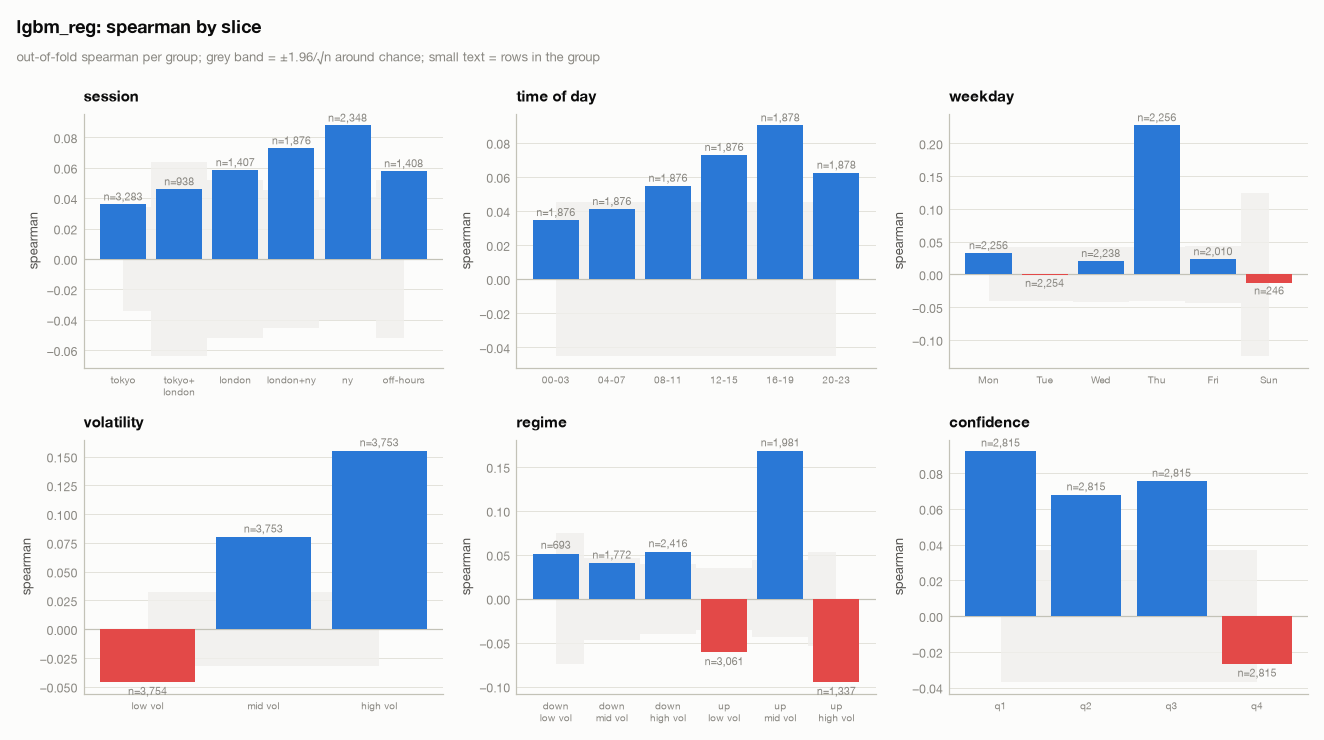

,n,spearman,hit_rate,strategy_bps
regime,,,,
down-trend / low vol,460,0.2458,0.6978,32.8219
down-trend / mid vol,1738,-0.0280,0.5426,5.6905
down-trend / high vol,2683,0.0478,0.5315,4.3027
up-trend / low vol,2019,-0.0703,0.4527,-1.4442
up-trend / mid vol,2978,0.0938,0.4906,6.1139
up-trend / high vol,1382,-0.1031,0.5326,2.5594


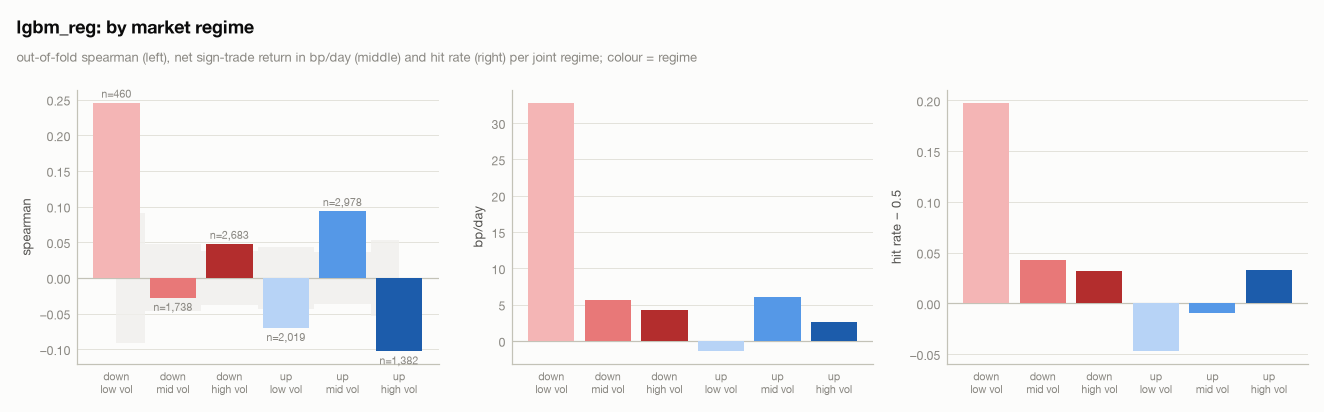

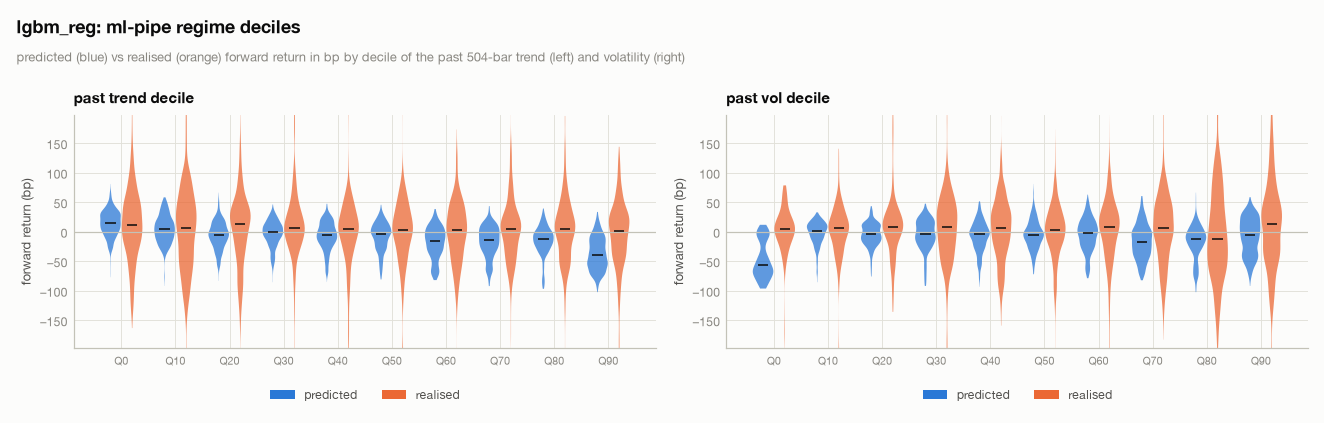

past trend                                             past vol                                            
                n spearman hit_rate mean_pred_bp mean_real_bp        n spearman hit_rate mean_pred_bp mean_real_bp
decile                                                                                                            
Q0           1113   0.0083   0.6047      14.2854      11.4548      370   0.0705   0.4135     -46.9260      -2.7093
Q10          1092  -0.1640   0.4359       4.5284       3.4656      974   0.1938   0.5688      -2.2233      -4.1862
Q20          1202   0.1040   0.5391      -6.0756       3.3662      776  -0.0785   0.4820      -4.9719       6.7039
Q30          1441   0.1308   0.6031      -3.4388      10.0351     1207  -0.0280   0.4789      -5.6800       3.7910
Q40          1296   0.0983   0.5262      -7.4476      -2.0173     1378  -0.0827   0.4717      -7.7355       3.5814
Q50           852   0.1222   0.5329      -8.3742      -5.4227     1448   0.1562   0.5414      -5.1673      -0.3607
Q60           771  -0.0718   0.4643     -19.0716      -4.3315     1551   0.0847   0.5409      -5.3946       2.0507
Q70           997   0.0158   0.4945     -17.1148       0.7839     1462   0.1265   0.4911     -16.3551       4.4300
Q80          1134   0.0593   0.4541     -15.4570       2.8182      984   0.1329   0.5874     -18.2644      -5.5103
Q90          1362  -0.0250   0.4648     -36.8459      -3.7904     1110   0.0068   0.5162      -8.1497       8.9503

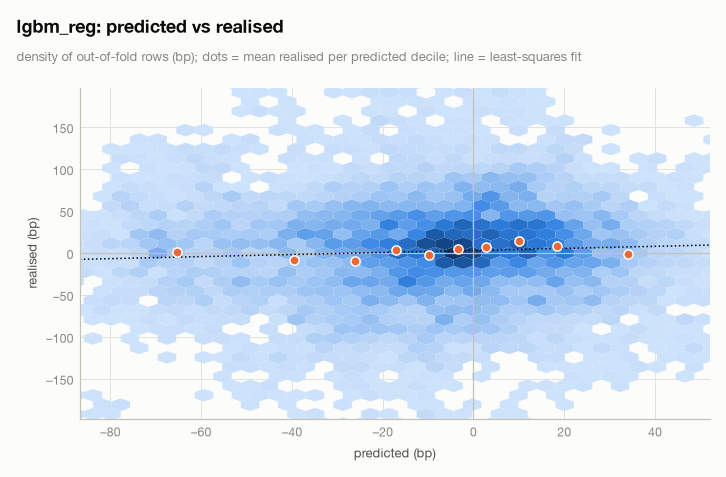

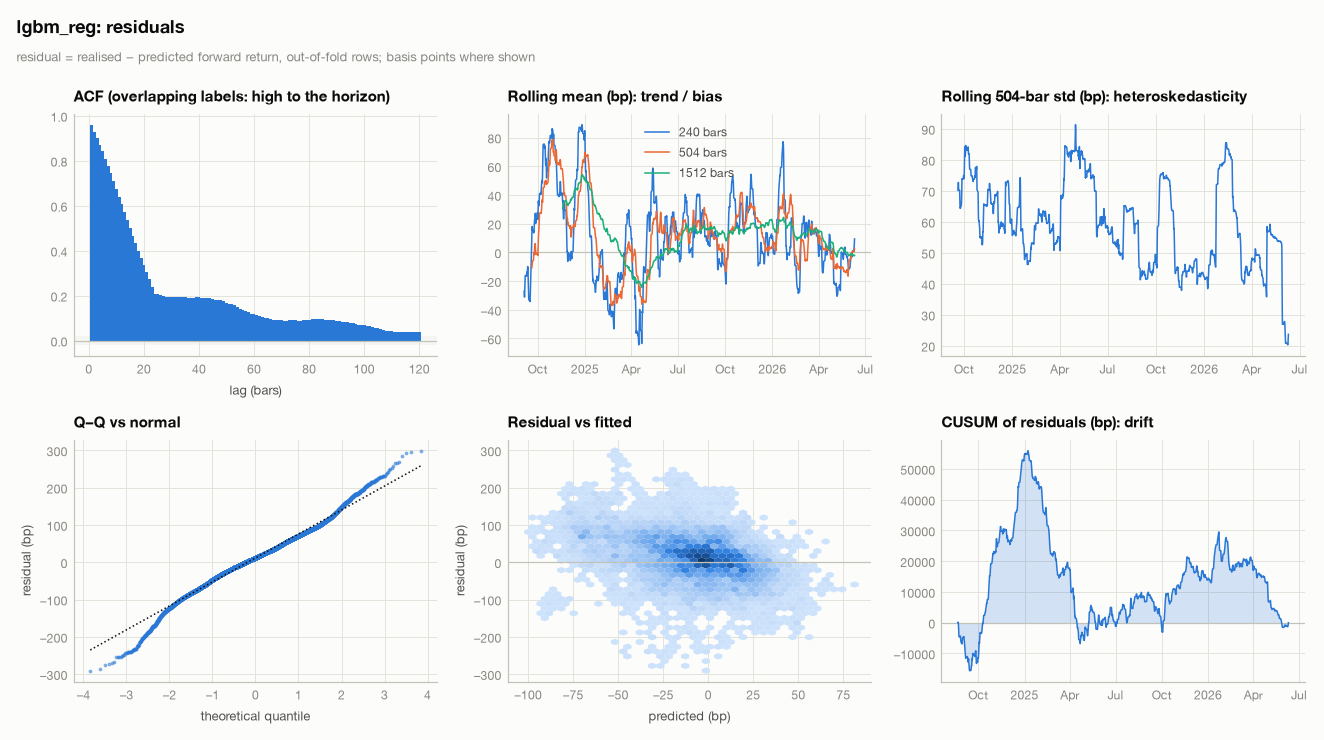

mean residual +11.63 bp (bias), std 64.7 bp, |ACF| beyond ±0.018 at 120/120 lags. Jarque-Bera p = 9.66e-207 (normality), ARCH-LM(24) p = 0 (volatility clustering); p < 0.05 rejects.

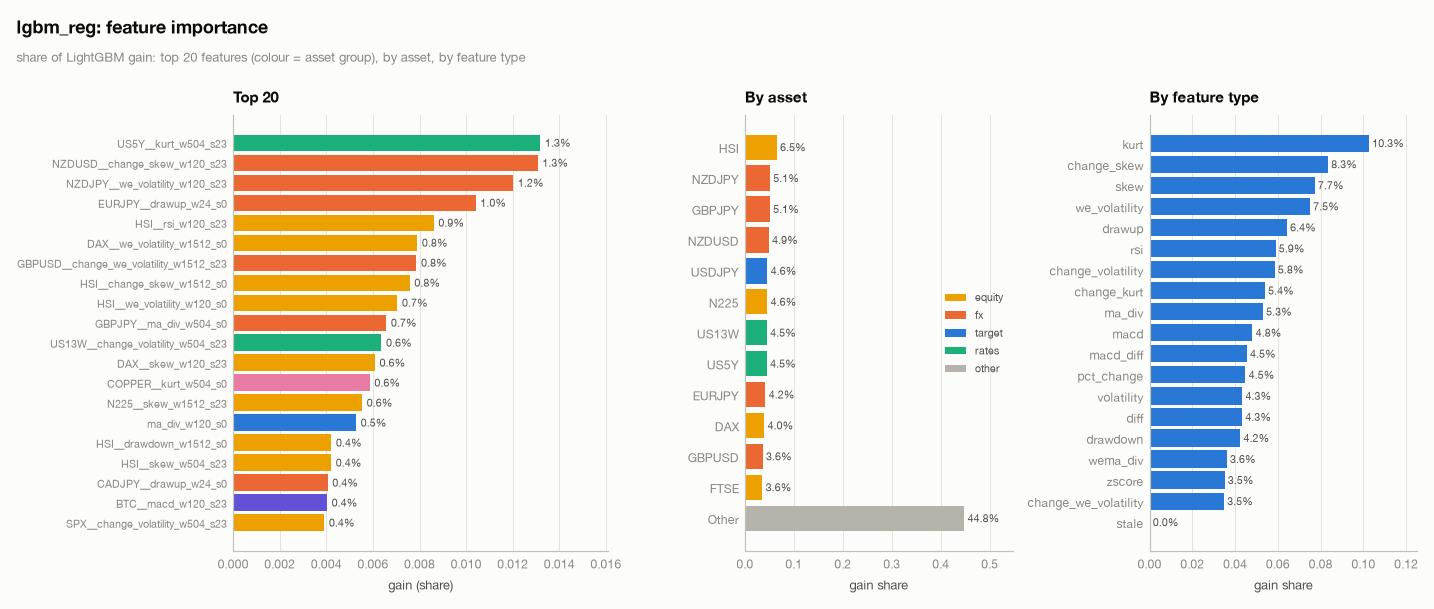

,spearman,spearman_fold_std,pearson,kendall,weighted_tau,r2,mse,mae,wasserstein,mcc,f1,precision,recall,roc_auc,bin_acc,sharpe_ratio,strategy_bps,sharpe,n,fit_time_s
model,,,,,,,,,,,,,,,,,,,,
lgbm_reg (CV),0.0599,0.1029,0.0572,0.0399,-0.1012,-0.2025,0.0000,0.0050,0.0025,0.0570,0.4905,0.5935,0.4180,0.5292,0.5152,1.0163,5.0469,1.3348,11260.0000,14.5076
lgbm_reg (holdout),0.0665,nan,0.0224,0.0458,0.0447,-0.0727,0.0000,0.0033,0.0021,0.0254,0.5252,0.6068,0.4629,0.5314,0.5036,-0.7001,3.2139,0.9957,2389.0000,nan


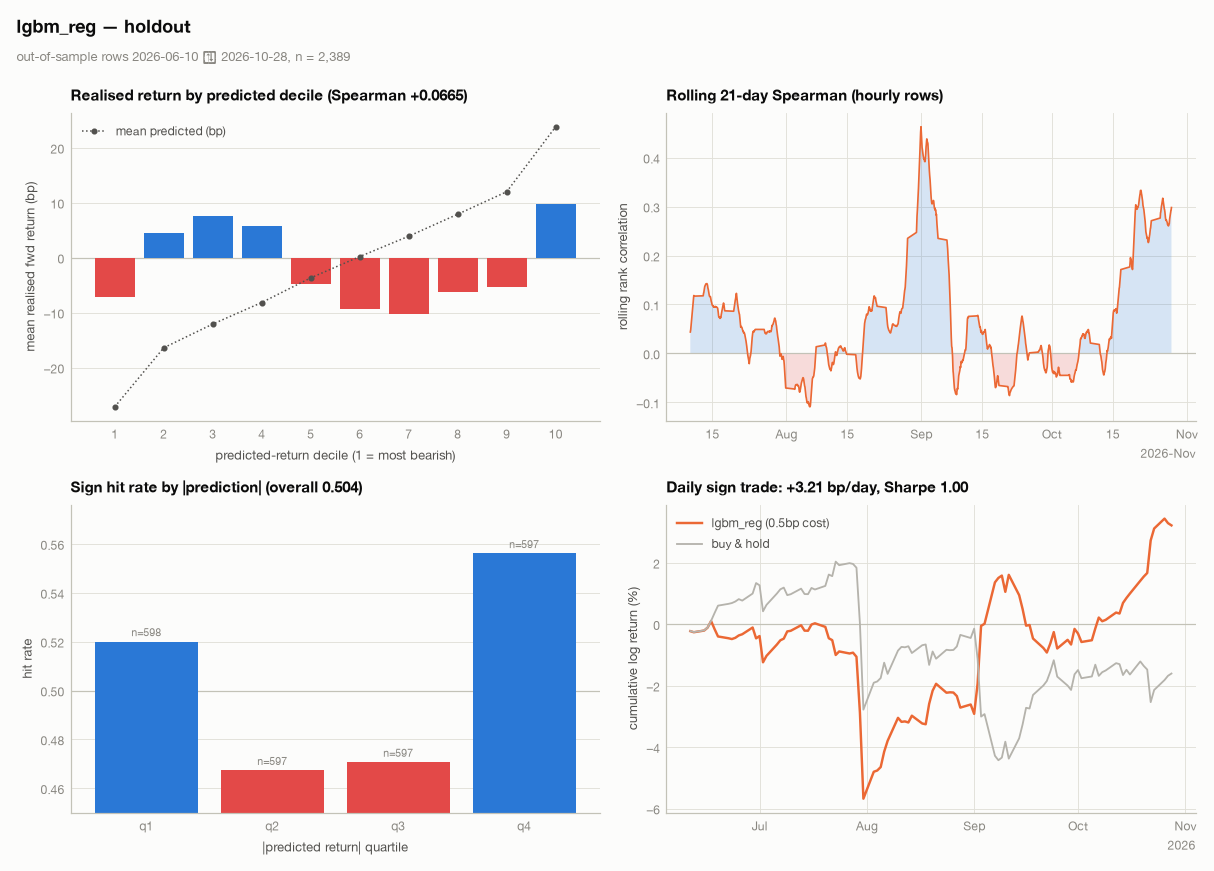

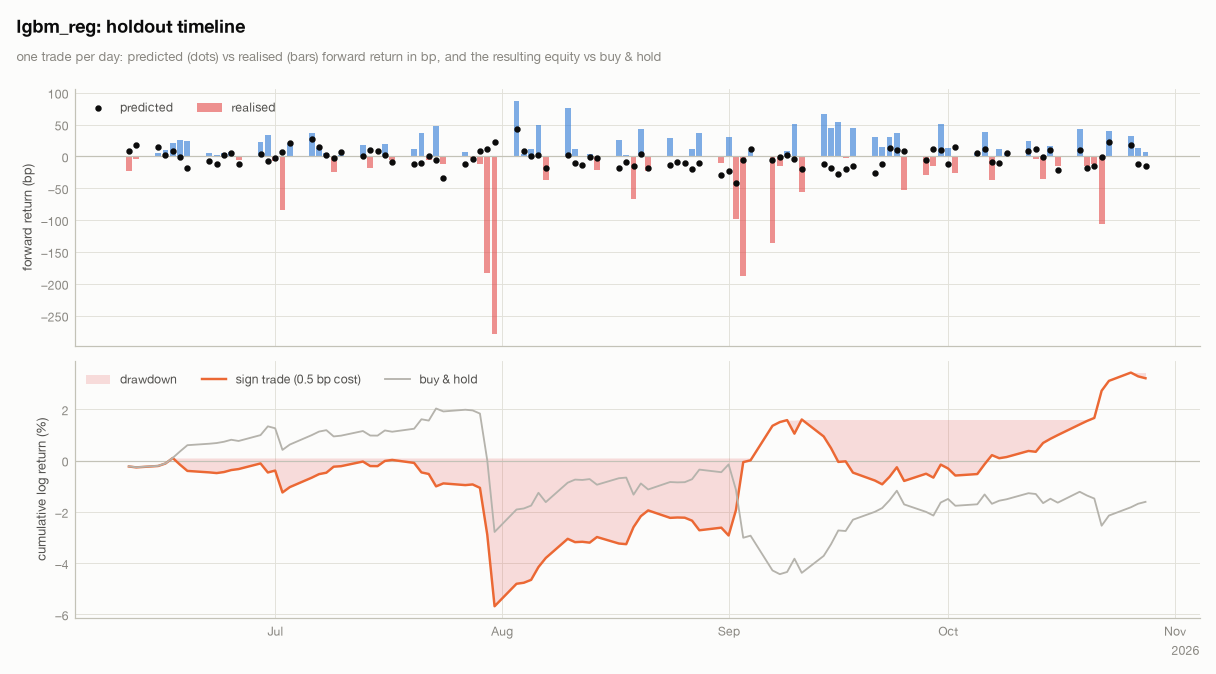

In [2]:
result = exp.run(display_preanalysis=True, display_postanalysis=True)

## Experiment ladder

`make experiments` evaluates a wider set of variants on v003's development rows and walk-forward folds
(holdout excluded): the v002 model variants plus asset-group ablations. The table is read from
`outputs/experiments.json`.

In [3]:
path = Path("outputs/experiments.json")
if path.exists():
    ladder = json.loads(path.read_text())
    board = pd.DataFrame(ladder["results"]).set_index("model")
    display_dataframe(board, f"{ladder.get('arm', '')} {ladder.get('task', 'direction')} task — {ladder['cv']}-fold walk-forward, "
                             f"gap {ladder['gap']}, dev rows {ladder['n_dev']:,} "
                             f"({ladder['dev_start'][:10]} → {ladder['dev_end'][:10]})")
else:
    display_info_box("outputs/experiments.json not found — run `make experiments`.", kind="warning")

,spearman,spearman_fold_std,kendall,pearson,r2,mcc,f1,bin_acc,strategy_bps,sharpe,rank_score,fit_time_s
model,,,,,,,,,,,,
lgbm_reg: windows >= 5 days,0.0850,0.0848,0.0566,0.0818,-0.1876,0.0742,0.5072,0.5251,4.8111,1.2719,79.7500,3.5746
lgbm_reg: basket without USDJPY,0.0656,0.0993,0.0437,0.0670,-0.1703,0.0691,0.5024,0.5222,5.9076,1.5648,77.7500,6.3186
lgbm_reg: huber objective,0.0656,0.0566,0.0432,0.0764,-0.0877,0.0262,0.5125,0.5074,3.3668,0.8882,73.5000,6.6658
lgbm_reg: no stale columns,0.0619,0.0894,0.0411,0.0661,-0.1837,0.0516,0.4889,0.5128,3.4854,0.9201,71.0000,6.3127
lgbm_reg: tuned (v002),0.0599,0.1029,0.0399,0.0572,-0.2025,0.0570,0.4905,0.5152,5.0469,1.3348,67.7500,11.8086
lgbm_reg: colsample 0.1,0.0564,0.0714,0.0377,0.0506,-0.2280,0.0560,0.4661,0.5102,4.1938,1.1079,62.0000,4.4920
lgbm_reg: USDJPY + equity/vol,0.0532,0.0633,0.0363,0.0499,-0.1610,0.0306,0.5216,0.5109,5.6365,1.4916,62.5000,2.9115
lgbm_reg: shift 0 only,0.0503,0.0965,0.0335,0.0358,-0.3191,0.0855,0.4359,0.5156,4.5143,1.1931,54.2500,3.9474
lgbm_reg: + calendar,0.0472,0.0891,0.0316,0.0393,-0.2322,0.0372,0.4501,0.5002,3.2099,0.8471,52.0000,6.3782


## Experiment lineage

Every arm in `usdjpy/exp/` carries a `DNA` dict (parents, goal, the stack of changes, the pipeline commit it was
authored against). `make train` records each full run under its arm in `experiment-lineage.json` (CV + holdout
metrics, git commit, seed); `make lineage` syncs the arms, renders `outputs/figures/lineage.png` and prints the
best-MCC path. The pipeline is still moving, so commit shas are informative, not exact.

```mermaid
graph TD
    v001_lgbm_walkforward["v001_lgbm_walkforward<br/>(not run)"]
    v002_fwd_logret_1d["v002_fwd_logret_1d<br/>(not run)"]
    v003_cross_asset["v003_cross_asset<br/>mcc 0.057 · spearman 0.060"]
    v001_lgbm_walkforward --> v002_fwd_logret_1d
    v002_fwd_logret_1d --> v003_cross_asset
    classDef best fill:#9ec5f4,stroke:#0ca30c,stroke-width:2px
    class v001_lgbm_walkforward,v002_fwd_logret_1d,v003_cross_asset best
```

![lineage](outputs/figures/lineage.png)

v001 and v002 predate the lineage file; their results live in the `note` of their DNA (and in the findings below).


In [ ]:
from usdjpy import lineage
path = Path("experiment-lineage.json")
if path.exists():
    lin = lineage.load(path)
    display(lineage.table(lin, metric="mcc").fillna(""))
    print("best path:", " -> ".join(lineage.best_path(lin, metric="mcc")))
else:
    print("no experiment-lineage.json yet: run `make lineage`")


## Headline figures

The full set is in `outputs/figures/` (and inline above when the notebook has been executed).

| | |
|---|---|
| ![market](outputs/figures/pre_market.png) | ![regimes](outputs/figures/pre_regimes_timeline.png) |
| ![basket](outputs/figures/pre_crossasset_corr.png) | ![leaderboard](outputs/figures/post_leaderboard.png) |
| ![timeline](outputs/figures/post_timeline.png) | ![regime performance](outputs/figures/post_regime_perf.png) |
| ![calendar](outputs/figures/post_calendar.png) | ![holdout](outputs/figures/post_holdout_timeline.png) |

## Findings (data 2024-01-15 → 2026-10-29)

### v003: cross-asset inputs (the main gap vs. ml-pipe)

* **Cross-asset features are the first thing that moves the needle.** Out-of-fold Spearman for
  `lgbm_reg` is **+0.060** (holdout Jun–Oct 2026: **+0.067**, 50.4% sign accuracy, +3.2 bp/day on the
  daily sign trade after costs). The USDJPY-only control on the *same folds* scores −0.016, i.e. the
  entire gain comes from the basket. `ridge` on the same inputs reaches +0.044, so it is not a
  LightGBM artefact. ml-pipe's `rank_score` agrees with the Spearman ordering.
* **It is not yet a robust result.** Per-fold Spearman is 0.05 / 0.13 / 0.23 / 0.03 / −0.08: most of
  the signal sits in 2025 and the most recent fold is negative. With 5 folds that is a t-statistic of
  about 1.6. Treat it as "worth pursuing", not as an edge. The rolling 1.5-year-window variant
  (ml-pipe's training schedule) gives the same +0.061.
* **Seeds agree on the ranking, not on the P&L.** Re-running `lgbm_reg` with seeds 1 and 2 (30% column
  sampling makes seeds matter) gives fold patterns 0.07/0.14/0.15/0.04/−0.05 and 0.09/0.09/0.18/0.02/0.00
  and holdout Spearman +0.048 / +0.082 (seed 0: +0.067). The daily sign trade on the holdout, though,
  is +3.2 / −3.6 / −1.4 bp per day across the three seeds: the rank correlation is reproducible, a
  tradeable signal is not.
* **Where it comes from.** FX crosses alone give +0.040, non-FX assets alone +0.019, both together
  +0.060 (so they are complementary). Feature importance is diffuse: no column carries more than 1.3%
  of the gain, and the top groups are rolling kurtosis / skew / weighted volatility of JPY crosses,
  Hang Seng, Nikkei, DAX and US 5y/13w yields, mostly at the 5-day and 21-day windows and often at
  the 1-day-ago shift. That diffuseness is exactly what ml-pipe's feature-selection stage is for (v004).
* **Ladder (22 variants, same folds).** Keeping only the 5-day / 21-day / 63-day windows is the best
  variant at **+0.085** (fold std 0.085); the ≤ 1-day windows alone are *negative* (−0.043), so the
  signal is slow cross-market positioning, not hourly co-movement. The basket *without* USDJPY still
  scores +0.066 and USDJPY alone −0.016. A Huber objective gives +0.066 with the tightest fold spread
  (0.057). By group: equity/vol indices +0.053, FX +0.040, rates +0.015, commodities +0.004. Removing the
  staleness columns, adding calendar columns, 10% column sampling and library-default LightGBM all land
  between +0.04 and +0.06; ridge +0.044.
* **The model memorises.** On the chronological 80/20 diagnostic fit the in-sample Spearman is 0.94
  and the out-of-sample Spearman −0.02 (generalization gap ≈ 0.95; that 20% block is the same
  Jan–Jun 2026 period as the negative fold). 400 trees over 7k columns fit the training set almost
  perfectly, and the confidence slices confirm the magnitudes mean little: the largest |predictions|
  hit 48%, the smallest 51–55%. Residuals show the expected overlapping-label autocorrelation
  (lag-1 ≈ 0.96) and ARCH effects (p ≈ 0). All of this argues for far fewer, selected features and
  stronger shrinkage (v004) rather than more trees.
* **Leakage checks.** Basket series are as-of joined on bar *start* stamps, so an exchange bar stamped
  14:30 (closing 15:30) is the latest print visible at the 15:00 USDJPY bar, whose own close is the
  16:00 price; nothing from after the USDJPY close enters a feature. Random-walk inputs still score
  ≈ 0 through the whole pipeline (tests), every feature is invariant to truncating or shocking the
  future, and the holdout is purged by 25 bars.

### v002: USDJPY-only, same objective

* No model predicts the 1-day return from USDJPY's own history: all within ±0.05 Spearman noise, the
  `random` baseline wins, the 14-variant ladder spans −0.07 to +0.01.

### v001: next-hour direction (kept for reference)

* LightGBM CV AUC 0.519 (holdout 0.558); mostly time-of-day; too small to survive 0.5 bp costs.

## Next arms

* `v004`: ml-pipe-style selection. Asset / feature-type pre-selection on the development rows by mean
  |Spearman| (the tables in the pre-analysis), then a stability-ranked (rolling 63-day Spearman /
  Pearson, EWMA-weighted) top-N feature selector *inside* the pipeline with N chosen by inner
  walk-forward, plus a |ρ| > 0.8 multicollinearity filter. The ladder says where to start: slow
  windows (≥ 5 days), equity + FX groups, Huber loss. Goal: keep the +0.06–0.09 while cutting 7k
  columns to a few hundred, which should tighten the fold spread and close the 0.95 generalization gap.
* `v005`: ml-pipe's exact retrain schedule (1.5-year training window, 16-day skip, 6-month roll,
  out-of-sample pooled) so the numbers line up with ml-pipe's reports one-to-one.
* Data: the free Yahoo feed caps us at ~2.8 years and hourly bars; 5 folds on that is why the fold
  spread is wide. The Tiingo / Sharadar parquet files ml-pipe uses (or a documented API, see
  `planning-1hour-price-direction-classification.md`) would add 4 years and 30-min bars.